# kNN — BRFSS GenHlth

Same loop as the Decision Tree notebook, using the shared harness from `common.py`. kNN is distance-based, so every estimator here goes through `scaled_pipeline` (StandardScaler fit on train only, wrapped with the classifier).

In [1]:
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import validation_curve, learning_curve, GridSearchCV, cross_val_score

from common import load_split, scaled_pipeline, CV, CV_SCORING, full_report, SEED

X_train, X_test, y_train, y_test = load_split()
X_train.shape, X_test.shape

((16000, 21), (4000, 21))

## Step 1: Baseline

Default k=5, Euclidean distance, uniform weighting -- but first we check whether distance weighting matters at all on this dataset before committing to a default, since the assignment requires justifying that choice rather than assuming it.

In [2]:
for weights in ["uniform", "distance"]:
    scores = cross_val_score(
        scaled_pipeline(KNeighborsClassifier(n_neighbors=11, weights=weights)),
        X_train, y_train, cv=CV, scoring=CV_SCORING, n_jobs=-1,
    )
    print(f"weights={weights:9s} CV Macro-F1: {scores.mean():.3f} +/- {scores.std():.3f}")

weights=uniform   CV Macro-F1: 0.381 +/- 0.008


weights=distance  CV Macro-F1: 0.386 +/- 0.010


**Result:** distance weighting (0.386 ± 0.010) edges out uniform (0.381 ± 0.008) at k=11, but the gap is within one standard deviation of the noise in the CV estimate -- not a meaningful difference on this dataset. We proceed with **uniform weighting** for the rest of this notebook: it is simpler, and the theoretical benefit of distance weighting (down-weighting farther neighbors) isn't realized here, plausibly because the features are already scaled and local density doesn't vary enough across the space for it to matter. Distance metric: Euclidean, the standard choice once features are on a common scale (justifying the scaling decision from the harness).

In [3]:
baseline = scaled_pipeline(KNeighborsClassifier(n_neighbors=5))
cv_scores = cross_val_score(baseline, X_train, y_train, cv=CV, scoring=CV_SCORING, n_jobs=-1)
baseline.fit(X_train, y_train)
train_macro_f1 = full_report("baseline-train", y_train, baseline.predict(X_train))[0]["macro_F1"]

print(f"k=5, uniform -- CV Macro-F1: {cv_scores.mean():.3f} +/- {cv_scores.std():.3f}")
print(f"k=5, uniform -- training Macro-F1: {train_macro_f1:.3f}")

k=5, uniform -- CV Macro-F1: 0.365 +/- 0.012
k=5, uniform -- training Macro-F1: 0.551


**Result:** CV Macro-F1 is 0.365 ± 0.012 against a training Macro-F1 of 0.551 -- a real but much smaller gap than the Decision Tree's unpruned 0.636. k=5 already smooths over the most extreme memorization (unlike a fully-grown tree), but there's still room to reduce variance further, which Step 2 explores directly.

## Step 2: Model-complexity curve (k)

Small k means a locally flexible, high-variance decision boundary (sensitive to individual noisy neighbors); large k oversmooths toward the global class distribution, high bias. We sweep a wide range spanning small, medium, and large neighborhoods.

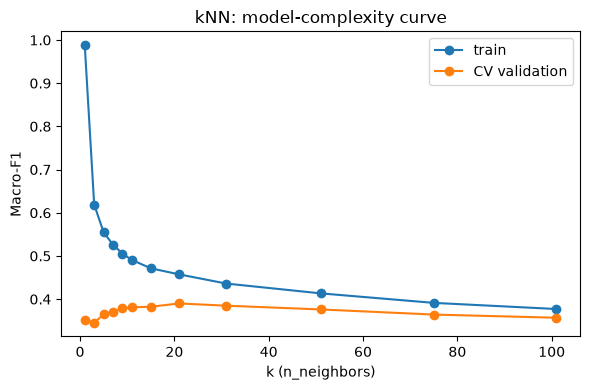

,k,train_F1,val_F1
0,1,0.988,0.352
1,3,0.619,0.346
2,5,0.555,0.365
3,7,0.526,0.371
4,9,0.505,0.379
5,11,0.491,0.381
6,15,0.471,0.382
7,21,0.457,0.390
8,31,0.436,0.385
9,51,0.413,0.376


In [4]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51, 75, 101]

train_scores, val_scores = validation_curve(
    scaled_pipeline(KNeighborsClassifier()), X_train, y_train,
    param_name="kneighborsclassifier__n_neighbors", param_range=k_values,
    cv=CV, scoring=CV_SCORING, n_jobs=-1,
)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(k_values, train_scores.mean(axis=1), marker="o", label="train")
ax.plot(k_values, val_scores.mean(axis=1), marker="o", label="CV validation")
ax.set_xlabel("k (n_neighbors)"); ax.set_ylabel("Macro-F1"); ax.legend()
ax.set_title("kNN: model-complexity curve")
plt.tight_layout()
plt.savefig("figures/knn_complexity_curve.png", dpi=200, bbox_inches="tight")
plt.show()

pd.DataFrame({"k": k_values, "train_F1": train_scores.mean(axis=1).round(3),
              "val_F1": val_scores.mean(axis=1).round(3)})

**Result:** At k=1, training Macro-F1 is 0.988 (each point is its own nearest neighbor -- pure memorization) while validation is only 0.352, the widest gap in the sweep. As k grows, training score falls steadily (0.988 → 0.377) while validation *rises* to a peak of 0.390 at k=21, then falls again to 0.357 by k=101 as the neighborhood becomes so large it approaches predicting the global class distribution (high bias). This is the same bias-variance shape as the Decision Tree's complexity curve, just parameterized by neighborhood size instead of depth: k=21 is the empirical sweet spot.

## Step 3: Learning curve

At k=5 (small, high-variance end), to see whether more data narrows the gap -- unlike the Decision Tree's capacity problem, kNN's variance is a function of local sample density, so more data can plausibly help even without changing k.

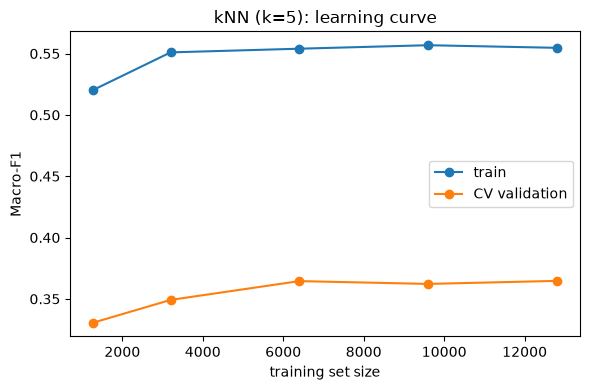

,train_size,train_F1,val_F1
0,1280,0.520,0.331
1,3200,0.551,0.349
2,6400,0.554,0.365
3,9600,0.557,0.362
4,12800,0.555,0.365


In [5]:
train_sizes = [0.1, 0.25, 0.5, 0.75, 1.0]

sizes_abs, lc_train, lc_val = learning_curve(
    scaled_pipeline(KNeighborsClassifier(n_neighbors=5)), X_train, y_train,
    train_sizes=train_sizes, cv=CV, scoring=CV_SCORING, n_jobs=-1,
)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(sizes_abs, lc_train.mean(axis=1), marker="o", label="train")
ax.plot(sizes_abs, lc_val.mean(axis=1), marker="o", label="CV validation")
ax.set_xlabel("training set size"); ax.set_ylabel("Macro-F1"); ax.legend()
ax.set_title("kNN (k=5): learning curve")
plt.tight_layout()
plt.savefig("figures/knn_learning_curve.png", dpi=200, bbox_inches="tight")
plt.show()

pd.DataFrame({"train_size": sizes_abs, "train_F1": lc_train.mean(axis=1).round(3),
              "val_F1": lc_val.mean(axis=1).round(3)})

**Result:** Unlike the Decision Tree's completely flat validation curve, kNN's validation Macro-F1 rises noticeably with more data (0.331 → 0.365) even with k fixed at 5, while training Macro-F1 stays roughly flat around 0.52-0.56. This makes sense mechanistically: kNN's effective "capacity" depends on local sample density, not a fixed parameter count, so adding data genuinely increases the resolution of each neighborhood regardless of k. Unlike the tree, more data plausibly *would* help kNN further -- a genuine point of difference between the two algorithm families worth carrying into the cross-model discussion.

## Step 4: Tune

In [6]:
coarse_best_k = k_values[int(np.argmax(val_scores.mean(axis=1)))]
fine_grid = sorted(set(max(1, coarse_best_k + d) for d in [-10, -5, 0, 5, 10]))
print("coarse best k from Step 2:", coarse_best_k)
print("fine grid to search:", fine_grid)

search = GridSearchCV(
    scaled_pipeline(KNeighborsClassifier()),
    param_grid={"kneighborsclassifier__n_neighbors": fine_grid},
    cv=CV, scoring=CV_SCORING, n_jobs=-1,
)
search.fit(X_train, y_train)
print("chosen k:", search.best_params_["kneighborsclassifier__n_neighbors"])
print("CV Macro-F1 at chosen k:", round(search.best_score_, 3))

coarse best k from Step 2: 21
fine grid to search: [11, 16, 21, 26, 31]


chosen k: 21
CV Macro-F1 at chosen k: 0.39


**Result:** The fine search confirms k=21 (CV Macro-F1 0.390), matching the coarse curve's peak exactly.

## Step 5: Refit and evaluate once on the held-out test set

In [7]:
best_k = search.best_params_["kneighborsclassifier__n_neighbors"]
final_knn = scaled_pipeline(KNeighborsClassifier(n_neighbors=best_k))

t0 = time.perf_counter()
final_knn.fit(X_train, y_train)
fit_time = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred = final_knn.predict(X_test)
predict_time = time.perf_counter() - t0

summary, cm, pc = full_report("kNN (tuned)", y_test, y_pred)
summary

{'model': 'kNN (tuned)',
 'accuracy': 0.444,
 'macro_F1': 0.41037298633360947,
 'balanced_acc': 0.386101666781009}

**Result:** The tuned kNN (k=21) scores 0.444 accuracy, **0.410 Macro-F1**, 0.386 balanced accuracy on the held-out test set -- essentially tied with the Decision Tree on accuracy (0.444 vs. 0.443) but slightly behind it on Macro-F1 (0.410 vs. 0.421) and balanced accuracy (0.386 vs. 0.401). The two models are close, but the tree currently has a small edge on the metrics that matter most for this imbalanced problem.

## Step 6: Runtime

In [8]:
print(f"fit time:     {fit_time*1000:.1f} ms")
print(f"predict time: {predict_time*1000:.1f} ms  (n_test={len(X_test)})")

fit time:     5.4 ms
predict time: 57.6 ms  (n_test=4000)


**Result:** Fit time is 5.4 ms (kNN "fitting" just stores the training data) but predict time is 57.6 ms for the 4,000-row test set -- roughly **11x slower to predict than to fit**, and about **29x slower to predict than the Decision Tree** (2.0 ms) on the identical test set. This is the classic kNN trade-off the FAQ describes: cheap fit, expensive prediction, since every query requires a distance computation against the full training set at k=21 neighbors.

## Step 7: Post-mortem

In [9]:
cm

,pred_1,pred_2,pred_3,pred_4,pred_5
true_1,239,400,71,4,0
true_2,241,875,273,14,1
true_3,100,557,465,65,6
true_4,10,108,211,139,30
true_5,2,6,39,86,58


In [10]:
pc.round(3)

,precision,recall,f1-score,support
1,0.404,0.335,0.366,714.0
2,0.450,0.623,0.522,1404.0
3,0.439,0.390,0.413,1193.0
4,0.451,0.279,0.345,498.0
5,0.611,0.304,0.406,191.0


**Interpretation:** Recall is highest for class 2 (0.623) and lowest for class 4 (0.279) -- a different weak spot than the Decision Tree, which struggled most with classes 1 and 5. Class 4's 359 errors split mainly toward class 3 (211, 59%) and class 5 (30, 8%), while class 5's 133 errors go predominantly to class 4 (86, 65%). The 4-5 boundary is confused in both directions, again consistent with the hypothesis's prediction that `BMI`'s plateau between these classes leaves little signal to separate them, regardless of algorithm family. Class 5 also has the highest precision of any class (0.611) despite low recall -- when kNN does predict class 5, it's usually right, but it predicts class 5 conservatively, consistent with a 21-neighbor vote rarely reaching consensus on the rarest class.